# Comparison of some models with the data

In [1]:
import sys
sys.path.append("../")
from utils import *

from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, make_scorer

from xgboost import XGBRegressor

from skopt import BayesSearchCV, gp_minimize, load
from skopt.plots import plot_objective, plot_convergence, plot_evaluations
from skopt.space import Space, Real, Integer, Categorical
from skopt.callbacks import CheckpointSaver

import warnings
warnings.filterwarnings("ignore")

## Importing data

In [2]:
#import the data and clean it a little
raw_data = pd.read_csv("../residential_solar_installations_panel_data_contiguous_US.csv", index_col=0)

features = ['avg GHI (W/m^2)',
            'ACS: number of households (2016)',
            'ACS: housing unit density (/mile^2, 2016)',
            'ACS: median household income (inflation adjusted $ in 2016, 2016)',
            'ACS: % housing units occupied (2016)',
            'ACS: % housing units occupied by renters (2016)',
            'ACS: avg number of years of education (2016)',
            'ACS: median age',
            'ACS: racial diversity (Gini Simpson index)']

columns = features + ['cumulative num of residential PVs by 2016', 'number of buildings']

raw_data = raw_data.dropna(axis=0, how='any', subset=columns) #drop all the rows that have any missing values in the columns we care about
raw_data = raw_data[raw_data['number of buildings']>0] #only keep rows with at least some buildings in them

In [3]:
#group by county
blockgroups_fips = [fips if len(fips)==12 else '0'+fips for fips in raw_data.index.astype(str).values]
county_codes = [fips[:5] for fips in blockgroups_fips]

raw_data['County code'] = county_codes

columns += ['County code']

raw_data = raw_data[columns].groupby('County code').agg({
    'avg GHI (W/m^2)':'mean', 
    'ACS: number of households (2016)':'sum', 
    'ACS: housing unit density (/mile^2, 2016)':'mean',
    'ACS: median household income (inflation adjusted $ in 2016, 2016)':'median', 
    'ACS: % housing units occupied (2016)':'mean', 
    'ACS: % housing units occupied by renters (2016)':'mean',
    'ACS: avg number of years of education (2016)':'mean', 
    'ACS: median age': 'median', 
    'ACS: racial diversity (Gini Simpson index)':'mean',
    'cumulative num of residential PVs by 2016':'sum',
    'number of buildings':'sum'
})

#add state features
raw_data['state'] = [states_dict[i] for i in  raw_data.index.str[:2]]
state_one_hot = pd.get_dummies(raw_data['state'])
raw_data = pd.concat([raw_data, state_one_hot], axis=1)
features += state_one_hot.columns.tolist()

In [4]:
X = raw_data[features].to_numpy()
y = (raw_data['cumulative num of residential PVs by 2016']/raw_data['number of buildings']).to_numpy().reshape(-1,1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y!=0)

In [5]:
from joblib import Parallel, delayed

def cv_one(model, X, y, train_idx, test_idx):
    model.fit(X[train_idx], y[train_idx])
    y_pred = model.predict(X[test_idx])
    y_pred[np.isnan(y_pred)] = 1e20
    return r2_score(y[test_idx], y_pred)

## RandomForest

In [8]:
rf_space = [
    Integer(10, 300, name='n_estimators'),
    Categorical([None, 5, 10, 15, 20, 25, 30, 35, 40], name='max_depth'),
    Integer(2, 10, name='min_samples_split'),
    Integer(1, 10, name='min_samples_leaf'),
    Categorical(["squared_error", "absolute_error", "friedman_mse", "poisson"], name='criterion')
]

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10)

def objective_rf(x):
    params = {v: xv for v, xv in zip([v.name for v in rf_space], x)}
    model = RandomForestRegressor(**params)
    # scores = cross_val_score(model, X_train, y_train, cv=rskf, n_jobs=8)
    scores = Parallel(n_jobs=8)(delayed(cv_one)(model, X_train, y_train, train, test) for train, test in rskf.split(X_train, y_train!=0))
    
    return -np.nanmean(scores)

def timer_callback(res):
    timer.end_iter()
    timer.start_iter()

In [12]:
n_calls = 100
timer = IterTimer(n_calls)

timer.start_iter()
rf_opt = gp_minimize(objective_rf, rf_space, n_calls=n_calls, callback=[timer_callback, CheckpointSaver(f"opt_results_RF.pkl")], acq_func='LCB', n_jobs=8, n_initial_points=20)

OSError: [Errno 22] Invalid argument

In [9]:
rf_opt = load(f"opt_results_RF.pkl")

In [29]:
best_x = rf_opt.x_iters[rf_opt.func_vals.argmin()]
best_params = {v: xv for v, xv in zip([v.name for v in rf_space], best_x)}
model = RandomForestRegressor(**best_params, n_jobs=8)
model.fit(X_train, y_train)

print(f"Best CV score: {-rf_opt.func_vals.min():.4f}")
print(f"Test score: {model.score(X_test, y_test):.4f}")
print(f"Best params: {str(best_params)}")

Best CV score: 0.6879
Test score: 0.7073
Best params: {'n_estimators': 264, 'max_depth': 40, 'min_samples_split': 2, 'min_samples_leaf': 2, 'criterion': 'absolute_error'}


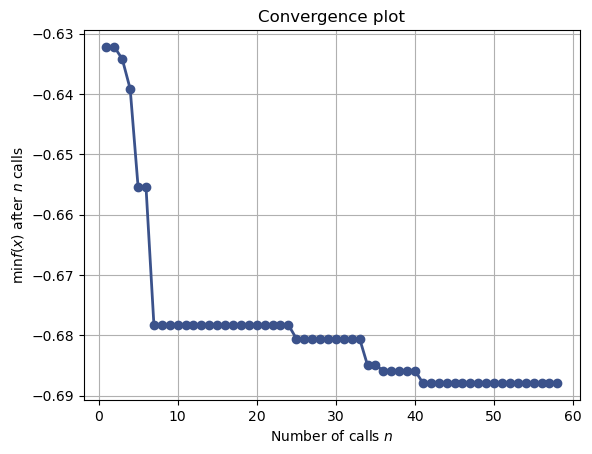

In [33]:
_ = plot_convergence(rf_opt)
plt.show()

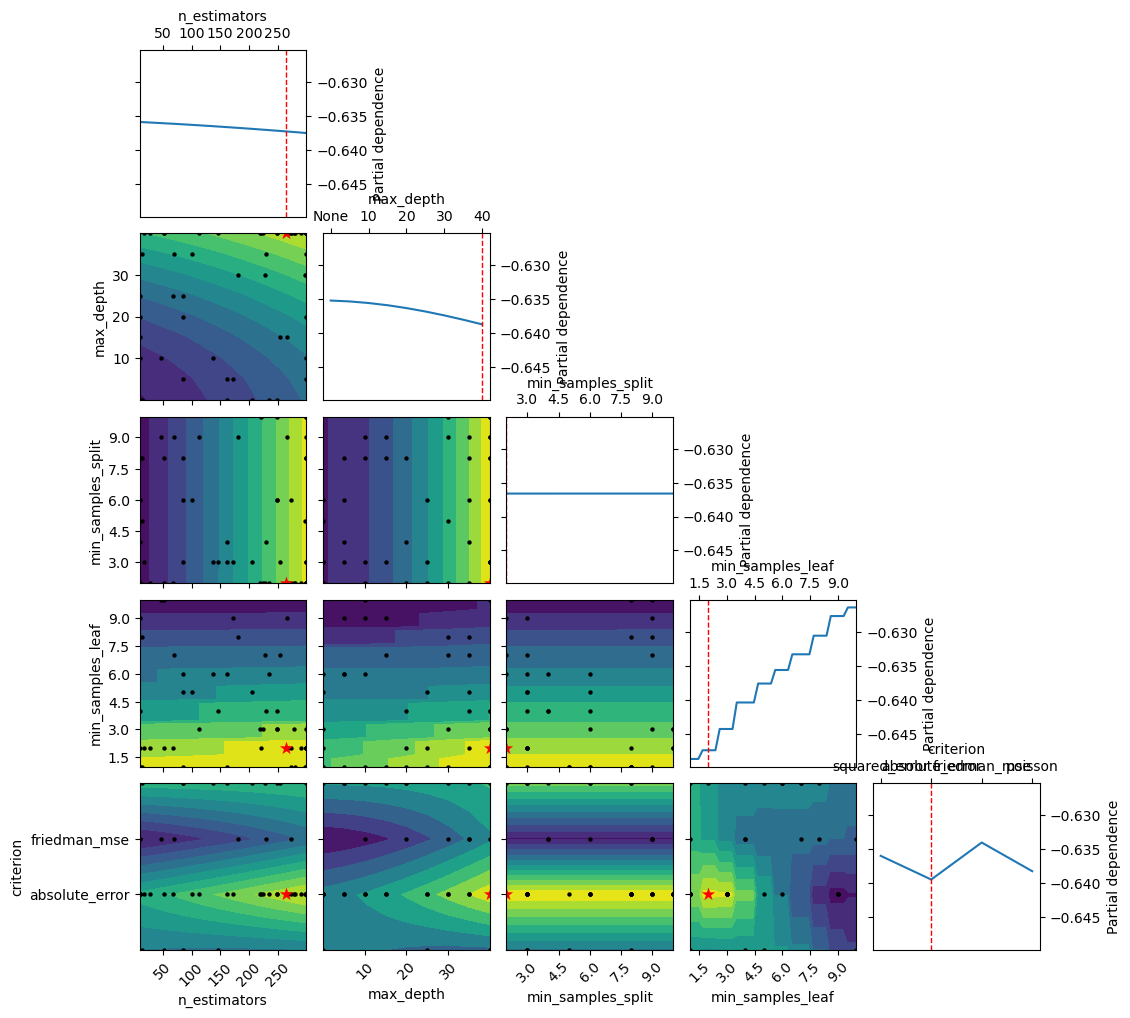

In [11]:
_ = plot_objective(rf_opt)
plt.show()

## XGBoost

In [10]:
xg_space = [
    Integer(10, 1000, name='n_estimators'),
    Integer(0, 50, name='max_leaves'),
    Real(1e-2, 10, prior='log-uniform', name='learning_rate'),
    Categorical([0, 5, 10, 15, 20, 25, 30, 35, 40], name='max_depth'),
]

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10)

def objective_xg(x):
    xc = x.copy()
    if xc[-1] == 0: xc[-1] = None
    params = {v: xv for v, xv in zip([v.name for v in xg_space], xc)}
    model = XGBRegressor(**params)
    scores = Parallel(n_jobs=8)(delayed(cv_one)(model, X_train, y_train, train, test) for train, test in rskf.split(X_train, y_train!=0))

    return -np.nanmean(scores)

def timer_callback(res):
    timer.end_iter()
    timer.start_iter()

In [14]:
n_calls = 100
timer = IterTimer(n_calls)

timer.start_iter()
xg_opt = gp_minimize(objective_xg, xg_space, n_calls=n_calls, callback=[timer_callback, CheckpointSaver(f"opt_results_XG.pkl")], acq_func='LCB', n_jobs=8, n_initial_points=20)

Iteration 100/100, ETA: 09:24:22 (average time per iteration: 6.392s)


In [15]:
best_x = xg_opt.x_iters[xg_opt.func_vals.argmin()]
best_params = {v: xv for v, xv in zip([v.name for v in xg_space], best_x)}
model = XGBRegressor(**best_params)
model.fit(X_train, y_train)

print(f"Best CV score: {-xg_opt.func_vals.min():.4f}")
print(f"Test score: {model.score(X_test, y_test):.4f}")
print(f"Best params: {str(best_params)}")

Best CV score: 0.6591
Test score: 0.7605
Best params: {'n_estimators': 407, 'max_leaves': 4, 'learning_rate': 0.08418557296214874, 'max_depth': 35}


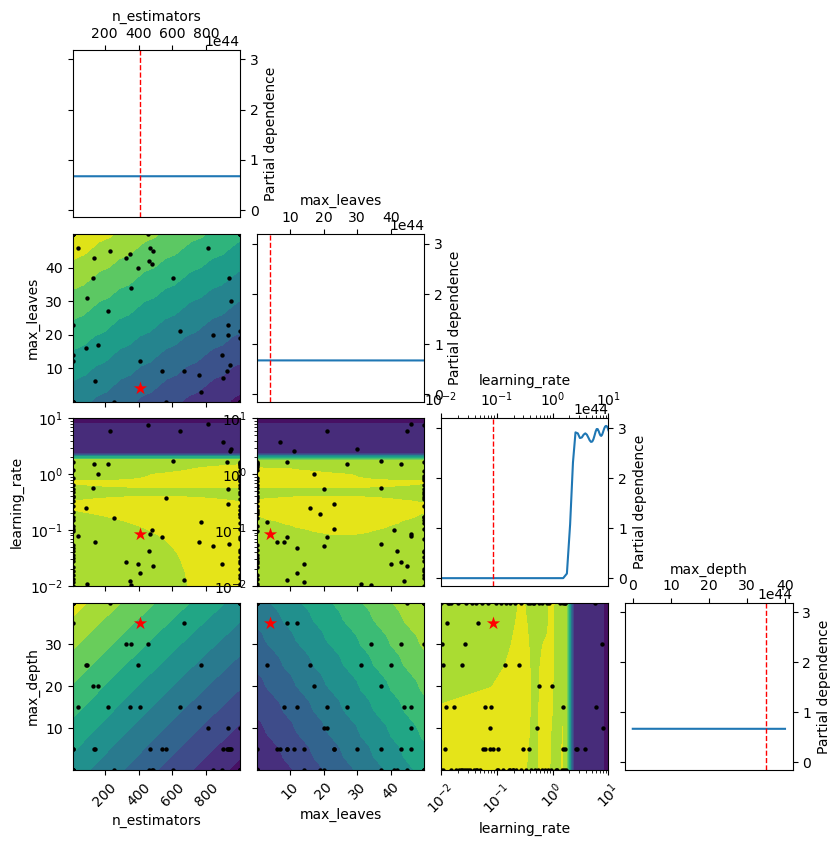

In [16]:
_ = plot_objective(xg_opt)
plt.show()

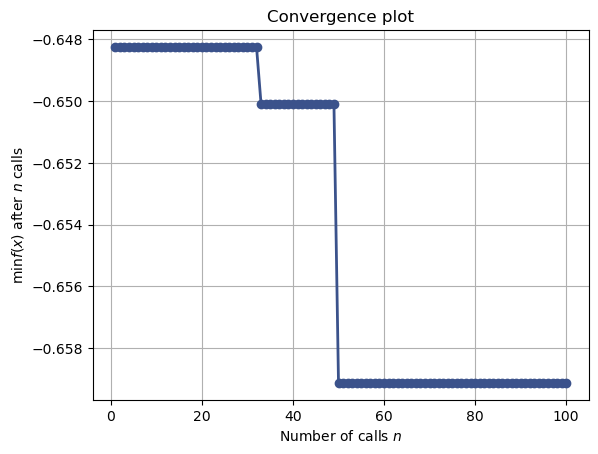

In [18]:
_ = plot_convergence(xg_opt)
plt.show()

## Best XGBoost

In [63]:
xg_opt = load("opt_results_XG.pkl")
best_x = xg_opt.x_iters[xg_opt.func_vals.argmin()]
best_params = {v: xv for v, xv in zip([v.name for v in xg_space], best_x)}
model = XGBRegressor(**best_params)
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.08418557296214874,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=35, max_leaves=4,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=407, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

In [60]:
features_plot = features
features_plot[:9] = ['avg GHI (W/m^2)',
            'number of households',
            'housing density (/mile^2)',
            'median income (inflation adjusted $)',
            '% housing occupied',
            '% housing occupied by renters',
            'avg years of education',
            'median age',
            'racial diversity (Gini Simpson index)']

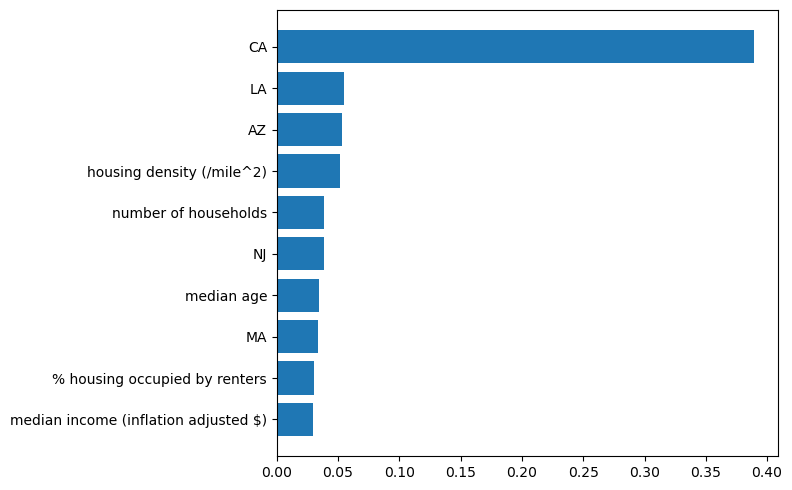

In [65]:
fig, ax = plt.subplots(figsize=(8, 5))

importances = model.feature_importances_
feat_plot = np.array(features_plot)[importances.argsort()[-10:]]

ax.barh(range(len(feat_plot)), importances[importances.argsort()[-10:]])
ax.set_yticks(range(len(feat_plot)))
ax.set_yticklabels(feat_plot);

fig.tight_layout()
# fig.savefig("XG_all_features.png", dpi=150)

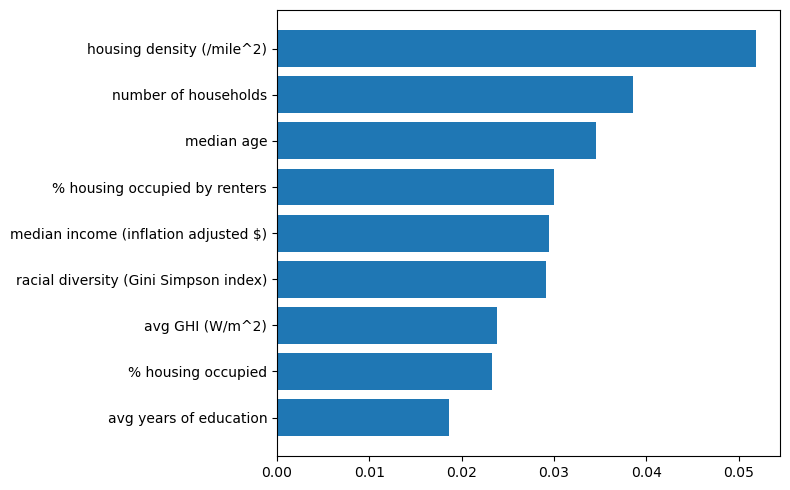

In [66]:
fig, ax = plt.subplots(figsize=(8, 5))

importances = model.feature_importances_[:9]
feat_plot = np.array(features_plot[:9])[importances.argsort()]

ax.barh(range(len(feat_plot)), importances[importances.argsort()])
ax.set_yticks(range(len(feat_plot)))
ax.set_yticklabels(feat_plot);

fig.tight_layout()
# fig.savefig("XG_features.png", dpi=150)

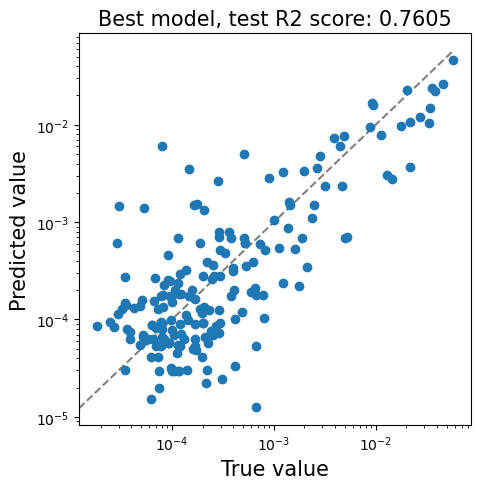

In [25]:
fig, ax = plt.subplots(figsize=(5, 5))

y_pred = model.predict(X_test)

minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax.scatter(y_test, y_pred, zorder=10)
ax.plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax.set_title(f"Best model, test R2 score: {model.score(X_test, y_test):.4f}", fontsize=15)
ax.set_xlabel("True value", fontsize=15)
ax.set_ylabel("Predicted value", fontsize=15)
# ax[1].set_xlim(minval, maxval)
# ax.set_ylim(minval, maxval)
ax.set_box_aspect(1)
ax.set_xscale('log')
ax.set_yscale('log')

fig.tight_layout()
# fig.savefig("XG_parity.png", dpi=150)

# Graveyard

In [49]:
rf_space = {
    'n_estimators': Integer(10, 1000),
    'max_depth': Categorical([None, 5, 10, 15, 20, 25, 30, 35, 40]),
    'min_samples_split': Integer(1, 10),
    'min_samples_leaf': Integer(1, 10),
    'criterion': Categorical(["squared_error", "absolute_error", "friedman_mse", "poisson"])
}

rkf = RepeatedKFold(n_splits=5, n_repeats=10)

In [50]:
rf_opt = BayesSearchCV(RandomForestRegressor(), rf_space, n_iter=50, cv=rkf, n_jobs=8)
rf_opt.fit(X_train, y_train)

print(f"Best CV score: {rf_opt.best_score_:.4f}")
print(f"Test score: {rf_opt.score(X_test, y_test):.4f}")
print(f"Best params: {str(rf_opt.best_params_)}")

Best CV score: 0.8501
Test score: 0.8561
Best params: OrderedDict([('criterion', 'poisson'), ('max_depth', 30), ('min_samples_leaf', 3), ('min_samples_split', 7), ('n_estimators', 67)])


In [30]:
xg_opt = BayesSearchCV(XGBRegressor(n_estimators=100), xg_space, n_iter=20, cv=rkf, n_jobs=8)
xg_opt.fit(X_train, y_train)

print(f"Best CV score: {xg_opt.best_score_:.4f}")
print(f"Test score: {xg_opt.score(X_test, y_test):.4f}")
print(f"Best params: {str(xg_opt.best_params_)}")

ValueError: Input contains NaN.